In [1]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm import tqdm
from datasets import load_dataset
from scipy import ndimage

In [2]:
#Device 
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce RTX 4090


In [3]:
#Import SAM2 
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 imported successfully")

SAM2 imported successfully


In [5]:
#Load SAM2 
checkpoint_candidates = [
    "/home/zahranadeem/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2_repo/checkpoints/sam2_hiera_small.pt",
]

checkpoint = None

for p in checkpoint_candidates:
    if os.path.exists(p):
        checkpoint = p
        break

print("Checkpoint:", checkpoint)

assert checkpoint is not None, "SAM2 checkpoint not found."

config = "sam2_hiera_s.yaml"

sam2_model = build_sam2(
    config,
    checkpoint,
    device=device
)

predictor = SAM2ImagePredictor(sam2_model)

print("SAM2 loaded successfully")

Checkpoint: /home/zahranadeem/checkpoints/sam2_hiera_small.pt
SAM2 loaded successfully


In [6]:
#Load VegANN and create validation split 

dataset = load_dataset("simonMadec/VegAnn")

split_dataset = dataset["train"].train_test_split(
    test_size=0.2,
    seed=42
)

train_dataset = split_dataset["train"]
val_dataset = split_dataset["test"]

print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))
print(val_dataset[0].keys())

Train size: 3020
Validation size: 755
dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


In [7]:
#Metric function 
def compute_iou_dice(pred_mask, gt_mask):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    iou = intersection / union if union > 0 else 0

    dice = (
        2 * intersection
    ) / (
        pred.sum() + gt.sum()
    ) if (pred.sum() + gt.sum()) > 0 else 0

    return iou, dice

In [8]:
def get_vegetation_box_from_image_full(image, padding=0, percentile=60):
    """
    Final setting from ablation:
    percentile = 60
    padding = 0

    This does NOT use GT mask.
    """

    img = image.astype(np.float32) / 255.0

    r = img[:, :, 0]
    g = img[:, :, 1]
    b = img[:, :, 2]

    exg = 2 * g - r - b

    threshold = np.percentile(exg, percentile)

    veg_mask = exg < threshold

    ys, xs = np.where(veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = image.shape[:2]

        box = np.array([
            W // 4,
            H // 4,
            3 * W // 4,
            3 * H // 4
        ])

        return box, veg_mask

    H, W = image.shape[:2]

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    box = np.array([x1, y1, x2, y2])

    return box, veg_mask

In [9]:
#Three Positive point helper 
def get_three_positive_points_from_estimated_mask(estimated_veg_mask):
    ys, xs = np.where(estimated_veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = estimated_veg_mask.shape

        return np.array([
            [W // 2, H // 2],
            [W // 3, H // 3],
            [2 * W // 3, 2 * H // 3]
        ])

    points = []

    points.append([
        int(xs.mean()),
        int(ys.mean())
    ])

    q1 = len(xs) // 4
    q3 = 3 * len(xs) // 4

    points.append([
        int(xs[q1]),
        int(ys[q1])
    ])

    points.append([
        int(xs[q3]),
        int(ys[q3])
    ])

    return np.array(points)

In [10]:
#SAM2 final prompt function 
def run_sam2_box_three_points_prompt(image, box, estimated_veg_mask):
    point_coords = get_three_positive_points_from_estimated_mask(
        estimated_veg_mask
    )

    point_labels = np.array([1, 1, 1])

    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        box=box,
        point_coords=point_coords,
        point_labels=point_labels,
        multimask_output=True
    )

    best_idx = scores.argmax()

    pred_mask = masks[best_idx] > 0

    return pred_mask, point_coords, scores[best_idx]


In [11]:
#Checking one Validation image 
idx = 0

sample = val_dataset[idx]

image = np.array(sample["image"])
mask = np.array(sample["mask"])

# VegAnn: vegetation = 0, background = 255
gt_mask = mask == 0

auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
    image,
    padding=0,
    percentile=60
)

pred_mask, point_coords, sam2_score = run_sam2_box_three_points_prompt(
    image,
    auto_box,
    estimated_veg_mask
)

iou, dice = compute_iou_dice(pred_mask, gt_mask)

print("Species:", sample["Species"])
print("Auto box:", auto_box)
print("Point coords:", point_coords)
print("SAM2 score:", sam2_score)
print(f"IoU: {iou*100:.2f}%")
print(f"Dice: {dice*100:.2f}%")

Species: Wheat
Auto box: [  0   0 511 511]
Point coords: [[306 219]
 [374  88]
 [507 368]]
SAM2 score: 0.62206566
IoU: 32.77%
Dice: 49.36%


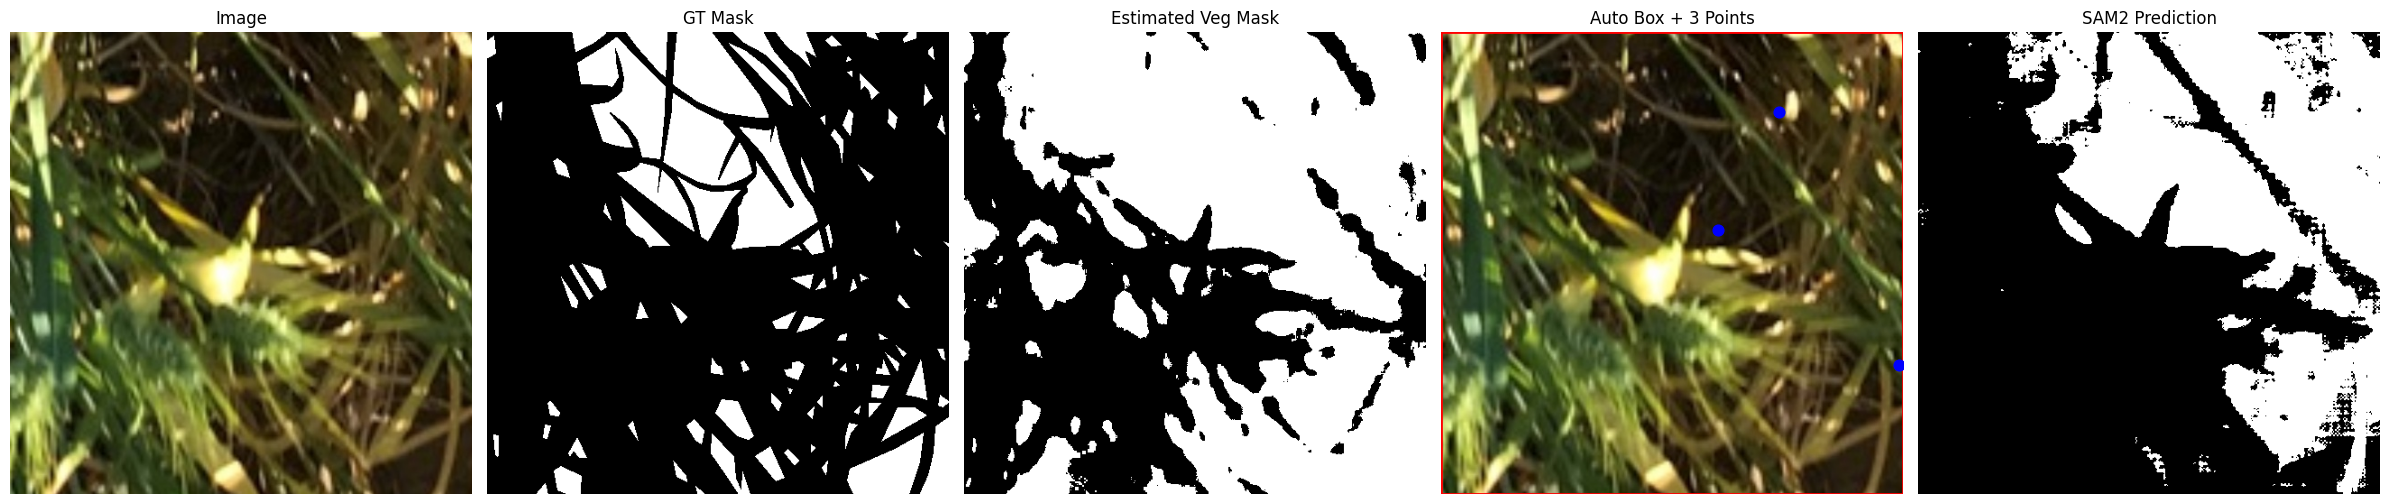

In [17]:
#Visualize sanity check 
import matplotlib.patches as patches
x1, y1, x2, y2 = auto_box

fig, axes = plt.subplots(1, 5, figsize=(24, 5))

axes[0].imshow(image)
axes[0].set_title("Image")
axes[0].axis("off")

axes[1].imshow(gt_mask, cmap="gray")
axes[1].set_title("GT Mask")
axes[1].axis("off")

axes[2].imshow(estimated_veg_mask, cmap="gray")
axes[2].set_title("Estimated Veg Mask")
axes[2].axis("off")

axes[3].imshow(image)
rect = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)
axes[3].add_patch(rect)

axes[3].scatter(
    point_coords[:, 0],
    point_coords[:, 1],
    c="blue",
    s=60
)

axes[3].set_title("Auto Box + 3 Points")
axes[3].axis("off")

axes[4].imshow(pred_mask, cmap="gray")
axes[4].set_title("SAM2 Prediction")
axes[4].axis("off")

plt.tight_layout()
plt.show()

In [15]:
#Final evaluation function 
def evaluate_final_pipeline(N=None):
    if N is None:
        N = len(val_dataset)

    N = min(N, len(val_dataset))

    results = []

    for idx in tqdm(range(N), desc=f"Evaluating {N} images"):

        sample = val_dataset[idx]

        image = np.array(sample["image"])
        mask = np.array(sample["mask"])

        gt_mask = mask == 0

        if gt_mask.sum() == 0:
            continue

        auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
            image,
            padding=0,
            percentile=60
        )

        pred_mask, point_coords, sam2_score = run_sam2_box_three_points_prompt(
            image,
            auto_box,
            estimated_veg_mask
        )

        iou, dice = compute_iou_dice(
            pred_mask,
            gt_mask
        )

        results.append({
            "idx": idx,
            "Species": sample["Species"],
            "IoU": iou,
            "Dice": dice,
            "SAM2 Score": float(sam2_score)
        })

    return pd.DataFrame(results)

In [16]:
#Running 500 validation images 
results_500 = evaluate_final_pipeline(500)

mean_iou_500 = results_500["IoU"].mean()
mean_dice_500 = results_500["Dice"].mean()

print(f"500 images Mean IoU: {mean_iou_500*100:.2f}%")
print(f"500 images Mean Dice: {mean_dice_500*100:.2f}%")

Evaluating 500 images: 100%|██████████| 500/500 [00:23<00:00, 21.16it/s]

500 images Mean IoU: 26.88%
500 images Mean Dice: 32.95%


In [18]:
#Running full validation split 
results_full = evaluate_final_pipeline(None)

mean_iou_full = results_full["IoU"].mean()
mean_dice_full = results_full["Dice"].mean()

print(f"Full validation Mean IoU: {mean_iou_full*100:.2f}%")
print(f"Full validation Mean Dice: {mean_dice_full*100:.2f}%")
print("Validation images evaluated:", len(results_full))

Evaluating 755 images: 100%|██████████| 755/755 [00:33<00:00, 22.25it/s]

Full validation Mean IoU: 26.09%
Full validation Mean Dice: 31.95%
Validation images evaluated: 753


In [19]:
#Final evaluation table 
final_eval_table = pd.DataFrame({
    "Evaluation Set": [
        "500 validation images",
        "Full validation split"
    ],
    "Mean IoU": [
        mean_iou_500,
        mean_iou_full
    ],
    "Mean Dice": [
        mean_dice_500,
        mean_dice_full
    ]
})

final_eval_percent = final_eval_table.copy()

final_eval_percent["Mean IoU"] = final_eval_percent["Mean IoU"].apply(
    lambda x: f"{x*100:.2f}%"
)

final_eval_percent["Mean Dice"] = final_eval_percent["Mean Dice"].apply(
    lambda x: f"{x*100:.2f}%"
)

final_eval_percent


,Evaluation Set,Mean IoU,Mean Dice
0,500 validation images,26.88%,32.95%
1,Full validation split,26.09%,31.95%


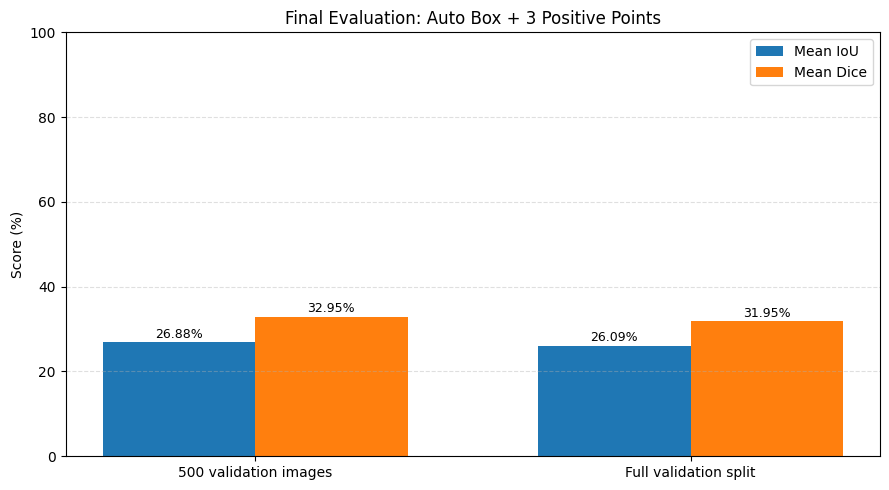

In [20]:
#Plot finall evaluation 
sets = final_eval_table["Evaluation Set"].tolist()

iou_scores = [
    x * 100 for x in final_eval_table["Mean IoU"].tolist()
]

dice_scores = [
    x * 100 for x in final_eval_table["Mean Dice"].tolist()
]

x = np.arange(len(sets))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    iou_scores,
    width,
    label="Mean IoU"
)

plt.bar(
    x + width / 2,
    dice_scores,
    width,
    label="Mean Dice"
)

plt.xticks(x, sets)
plt.ylabel("Score (%)")
plt.title("Final Evaluation: Auto Box + 3 Positive Points")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(iou_scores):
    plt.text(
        i - width / 2,
        v + 1,
        f"{v:.2f}%",
        ha="center",
        fontsize=9
    )

for i, v in enumerate(dice_scores):
    plt.text(
        i + width / 2,
        v + 1,
        f"{v:.2f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "final_auto_box_3_points_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
#Save CSV files 
results_500.to_csv(
    "final_500_validation_results.csv",
    index=False
)

results_full.to_csv(
    "final_full_validation_results.csv",
    index=False
)

final_eval_table.to_csv(
    "final_evaluation_summary.csv",
    index=False
)

final_eval_percent.to_csv(
    "final_evaluation_summary_percent.csv",
    index=False
)

print("Saved final evaluation results.")

Saved final evaluation results.


In [22]:
#Development of Auto Prompt Pipeline
summary_table = pd.DataFrame({

    "Experiment":[
        "50 Images",
        "100 Images",
        "200 Images (Box Only)",
        "200 Images (Best Prompt)"
    ],

    "Configuration":[
        "Auto Box",
        "Auto Box",
        "Auto Box",
        "Auto Box + 3 Positive Points"
    ],

    "Mean IoU (%)":[
        17.30,
        21.78,
        19.44,
        26.00
    ],

    "Mean Dice (%)":[
        21.16,
        25.81,
        23.86,
        31.85
    ]

})

summary_table

,Experiment,Configuration,Mean IoU (%),Mean Dice (%)
0,50 Images,Auto Box,17.30,21.16
1,100 Images,Auto Box,21.78,25.81
2,200 Images (Box Only),Auto Box,19.44,23.86
3,200 Images (Best Prompt),Auto Box + 3 Positive Points,26.00,31.85


In [23]:
#Final Evaluation 
final_table = pd.DataFrame({

    "Evaluation":[
        "500 Validation Images",
        "Full Validation Split (753)"
    ],

    "Best Configuration":[
        "ExG60 + Padding0 + Box + 3 Positive Points",
        "ExG60 + Padding0 + Box + 3 Positive Points"
    ],

    "Mean IoU (%)":[
        26.88,
        26.09
    ],

    "Mean Dice (%)":[
        32.95,
        31.95
    ]

})

final_table

,Evaluation,Best Configuration,Mean IoU (%),Mean Dice (%)
0,500 Validation Images,ExG60 + Padding0 + Box + 3 Positive Points,26.88,32.95
1,Full Validation Split (753),ExG60 + Padding0 + Box + 3 Positive Points,26.09,31.95


In [24]:
overall_summary = pd.DataFrame({

    "Experiment":[
        "Initial Evaluation",
        "Auto Box Baseline",
        "ExG Parameter Selection",
        "Prompt Ablation",
        "Final Evaluation",
        "Final Evaluation"
    ],

    "Images":[
        50,
        100,
        200,
        200,
        500,
        753
    ],

    "Configuration":[
        "Auto Box",
        "Auto Box",
        "ExG60 + Pad0",
        "ExG60 + Pad0 + 3 Positive Points",
        "ExG60 + Pad0 + 3 Positive Points",
        "ExG60 + Pad0 + 3 Positive Points"
    ],

    "Mean IoU (%)":[
        17.30,
        21.78,
        19.44,
        26.00,
        26.88,
        26.09
    ],

    "Mean Dice (%)":[
        21.16,
        25.81,
        23.86,
        31.85,
        32.95,
        31.95
    ]

})

overall_summary

,Experiment,Images,Configuration,Mean IoU (%),Mean Dice (%)
0,Initial Evaluation,50,Auto Box,17.30,21.16
1,Auto Box Baseline,100,Auto Box,21.78,25.81
2,ExG Parameter Selection,200,ExG60 + Pad0,19.44,23.86
3,Prompt Ablation,200,ExG60 + Pad0 + 3 Positive Points,26.00,31.85
4,Final Evaluation,500,ExG60 + Pad0 + 3 Positive Points,26.88,32.95
5,Final Evaluation,753,ExG60 + Pad0 + 3 Positive Points,26.09,31.95
